In [10]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")

include("../util_shoji.jl")


SOR (generic function with 1 method)

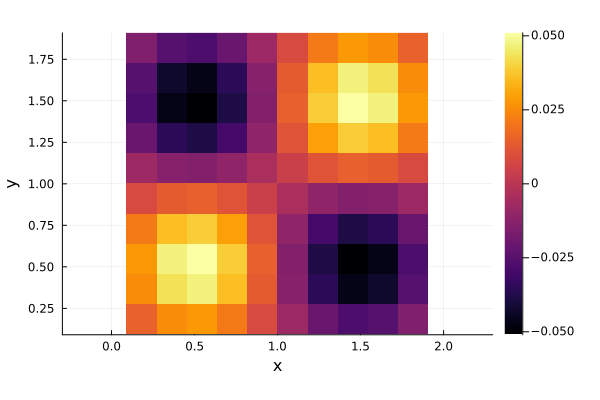

In [11]:
using LinearAlgebra
using Plots

jitter = 1e-20


Nx = 10
Ny = 10

Lx = 2.0
Ly = 2.0

dx = Lx/(Nx+1)
dy = Ly/(Ny+1)

x = range(dx, step=dx, length=Nx)
y = range(dy, step=dy, length=Ny)

f = zeros(Nx,Ny)

for j in 1:Ny
    for i in 1:Nx
        f[i,j] = -sin(pi*x[i])*sin(pi*y[j])
    end
end

index(i,j) = i + (j-1)*Nx

N = Nx*Ny
A = zeros(N,N)

for j in 1:Ny
    for i in 1:Nx

        k = index(i,j)

        A[k,k] = -4

        if i>1
            A[k,index(i-1,j)] = 1
        end

        if i<Nx
            A[k,index(i+1,j)] = 1
        end

        if j>1
            A[k,index(i,j-1)] = 1
        end

        if j<Ny
            A[k,index(i,j+1)] = 1
        end
    end
end

A ./= dx^2

b = reshape(f, N)

u = A \ b

U = reshape(u, Nx, Ny)

using Plots

heatmap(x, y, U',
    xlabel="x",
    ylabel="y",
    aspect_ratio=1,
    right_margin=10Plots.mm)

max_error:0.001371816530729042


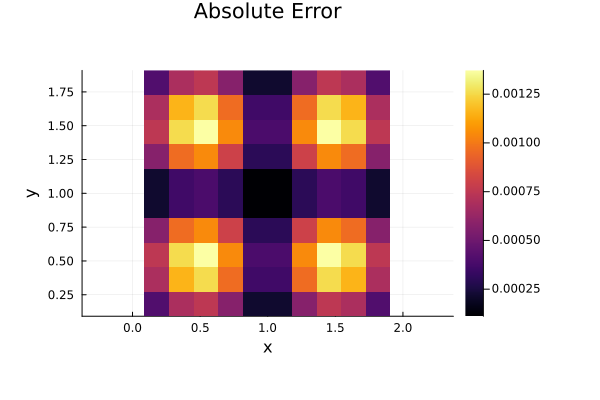

In [12]:
U_exact = zeros(Nx, Ny)

for j in 1:Ny
    for i in 1:Nx
        U_exact[i,j] = (1/(2*pi^2))*sin(pi*x[i])*sin(pi*y[j])
    end
end

println("max_error:", maximum(abs.(U .- U_exact)))

E = U .- U_exact

heatmap(
    x, y, abs.(E)',
    xlabel="x",
    ylabel="y",
    title="Absolute Error",
    aspect_ratio=1,
    margin=6Plots.mm,
    right_margin=20Plots.mm
)

X_train size = (100,)
y_train size = (100,)
H size = (100, 100)
K size = (100, 100)
Ks size = (100, 100)
Maximum error = 0.001347812384999647


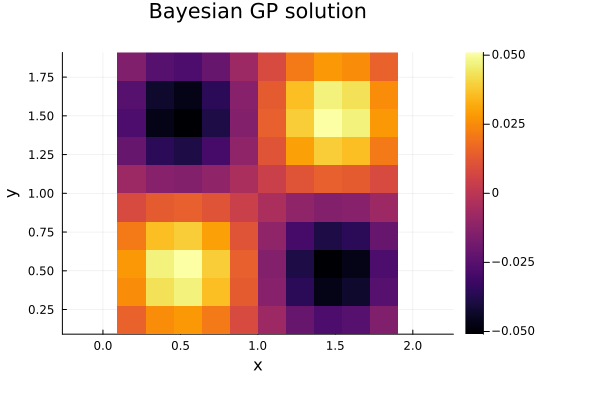

In [13]:


# -------------------------
# Training points
# -------------------------

X_train = [
    [x[i], y[j]]
    for j in 1:Ny
    for i in 1:Nx
]


y_train = zeros(N)


for j in 1:Ny
    for i in 1:Nx

        k = index(i,j)

        y_train[k] =
            -sin(pi*x[i])*sin(pi*y[j])

    end
end


println("X_train size = ", size(X_train))
println("y_train size = ", size(y_train))



# -------------------------
# Hyper parameters
# -------------------------

ℓ = 1.0
σf = 1.0
C = 0.001



# -------------------------
# Test points
# -------------------------

X_test = [
    [x[i], y[j]]
    for j in 1:Ny
    for i in 1:Nx
]



# -------------------------
# Observation matrix
# Laplacian operator
# -------------------------

H = zeros(N,N)


for j in 1:Ny
    for i in 1:Nx

        k = index(i,j)

        H[k,k] = -4.0


        if i > 1
            H[k,index(i-1,j)] = 1.0
        end

        if i < Nx
            H[k,index(i+1,j)] = 1.0
        end

        if j > 1
            H[k,index(i,j-1)] = 1.0
        end

        if j < Ny
            H[k,index(i,j+1)] = 1.0
        end

    end
end


H ./= dx^2


println("H size = ", size(H))



# -------------------------
# Covariance matrix
# -------------------------

K0 =
    kernel_matrix(X_train,X_train;
                  ℓ=ℓ,
                  σf=σf)



K =
    H*K0*H' +
    C*(dx^2)*I(N)+
    (C*dx^2 + jitter) * I(N)



println("K size = ", size(K))



# -------------------------
# Cross covariance
# -------------------------

Ks =
    kernel_matrix(X_train,X_test;
                  ℓ=ℓ,
                  σf=σf)


Ks = H*Ks



println("Ks size = ", size(Ks))



# -------------------------
# Posterior mean
# -------------------------

μ =
    transpose(Ks) *
    (K \ y_train)



# -------------------------
# Posterior covariance
# -------------------------

Kss =
    kernel_matrix(X_test,X_test;
                  ℓ=ℓ,
                  σf=σf)



Σ =
    Kss -
    transpose(Ks) *
    (K \ Ks)


std =
    sqrt.(abs.(diag(Σ)))



# -------------------------
# Reshape
# -------------------------

U =
reshape(μ,Nx,Ny)



# -------------------------
# Exact solution
# -------------------------

U_exact=zeros(Nx,Ny)


for j in 1:Ny
    for i in 1:Nx

        U_exact[i,j] =
            (1/(2*pi^2)) *
            sin(pi*x[i]) *
            sin(pi*y[j])

    end
end



error =
maximum(abs.(U-U_exact))
println("Maximum error = ",error)



# -------------------------
# Plot
# -------------------------

heatmap(
    x,
    y,
    U',
    xlabel="x",
    ylabel="y",
    title="Bayesian GP solution",
    aspect_ratio=1,
    right_margin=20Plots.mm
)



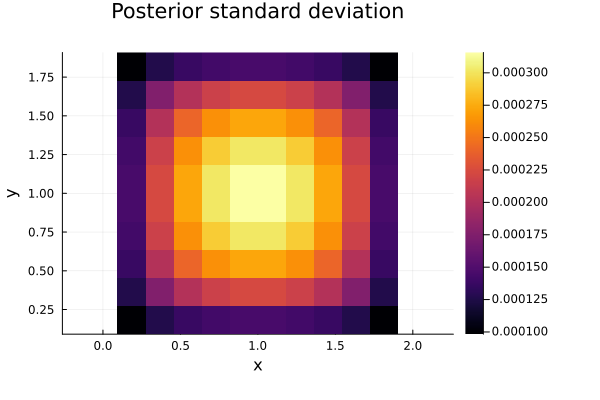

In [14]:
STD = reshape(std,Nx,Ny)

heatmap(
    x,
    y,
    STD',
    xlabel="x",
    ylabel="y",
    title="Posterior standard deviation",
    aspect_ratio=1,
    right_margin=20Plots.mm
)

In [15]:
function log_marginal_H(
    X_train,
    y;
    H,
    dx,
    ℓ,
    σf,
    C,
    prior_mean = 0.0
)

    jitter = 1e-20

    K =
        H *
        kernel_matrix(
            X_train,
            X_train;
            ℓ = ℓ,
            σf = σf
        ) *
        H' +
        (C*dx^2 + jitter) * I(length(y))


    m = fill(prior_mean, length(y))


    try
        L = cholesky(Hermitian(K)).L

        α = L' \ (L \ (y - m))

        logdetK = 2sum(log.(diag(L)))

        return -0.5 * (y - m)' * α -
               0.5 * logdetK -
               0.5 * length(y) * log(2π)

    catch
        return -Inf
    end

end

log_marginal_H (generic function with 1 method)

In [16]:
ℓ_grid = [
    0.001,
    0.1,
    0.5,
    1.0,
    2.0,
    5.0,
    10.0,
    100.0,
    1000.0
]

σf_grid = [
    0.0001,
    0.001,
    0.01,
    0.03,
    0.1,
    0.3,
    1.0,
    3.0,
    10.0,
    30.0,
    100.0,
    500.0,
    1000.0,
    10000.0
]

scores = zeros(length(ℓ_grid), length(σf_grid))

for (i,ℓ) in enumerate(ℓ_grid)
    for (j,σf) in enumerate(σf_grid)

        scores[i,j] =
            log_marginal_H(
                X_train,
                y_train;
                H = H,
                dx = dx,
                ℓ = ℓ,
                σf = σf,
                C = C,
                prior_mean = 0.0
            )

    end
end

best_linear_idx = argmax(scores)

best_i, best_j =
    Tuple(CartesianIndices(scores)[best_linear_idx])

ℓ = ℓ_grid[best_i]
σf = σf_grid[best_j]

println("Best ℓ = ", ℓ)
println("Best σf = ", σf)

Best ℓ = 1.0
Best σf = 1.0
